In [1]:
import sys
print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful!")

d:\ML-Projects\customer-churn-prediction\.venv312\Scripts\python.exe
All imports successful!


In [2]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

In [7]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [9]:
df.dropna(subset=["TotalCharges"], inplace=True)

df.isnull().sum().sum()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_14512\519979165.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["TotalCharges"], inplace=True)


np.int64(0)

In [10]:
df = df.dropna(subset=["TotalCharges"])

df.isnull().sum().sum()

np.int64(0)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

26.6% of customers churned.

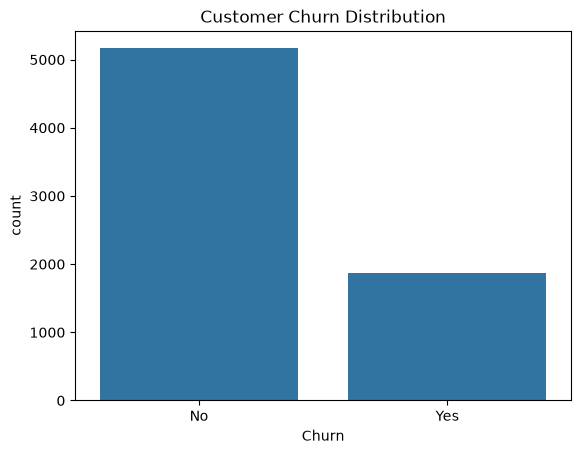

In [13]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

In [15]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


tenure: Average customer stays for about 32 months.

MonthlyCharges: Average monthly charge is $64.80.

TotalCharges: Average total charge is $2,283.30.

tenure ranges from 1 to 72 months.

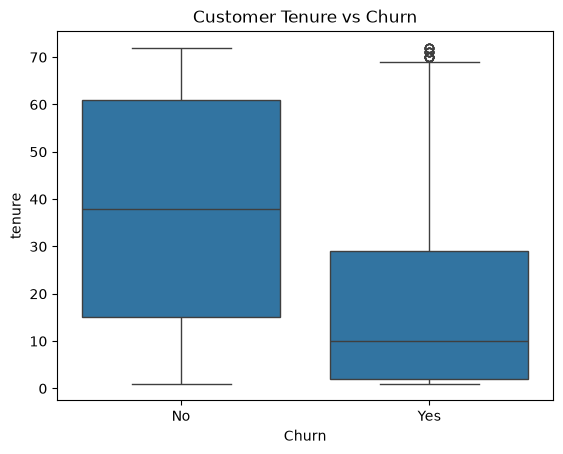

In [16]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()

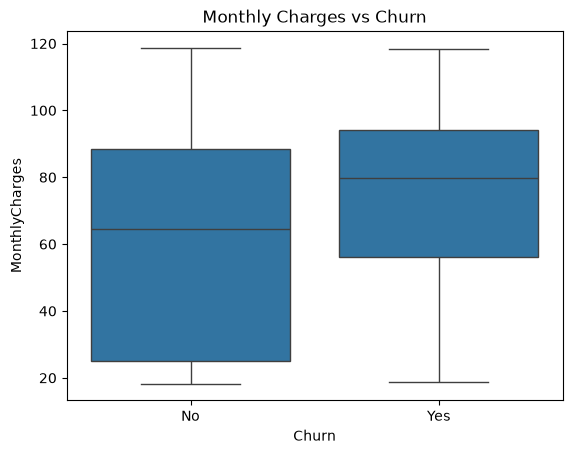

In [17]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

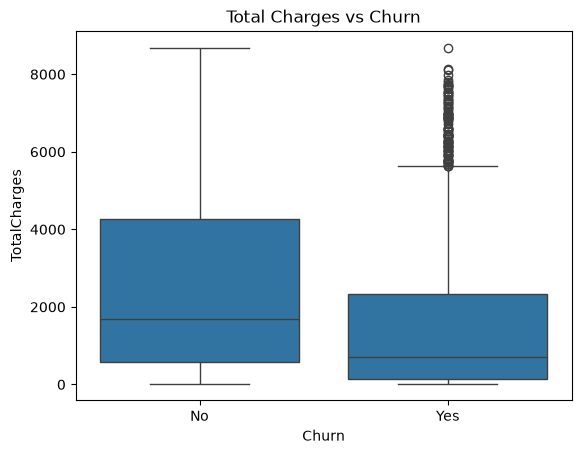

In [24]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Total Charges vs Churn")
plt.show()

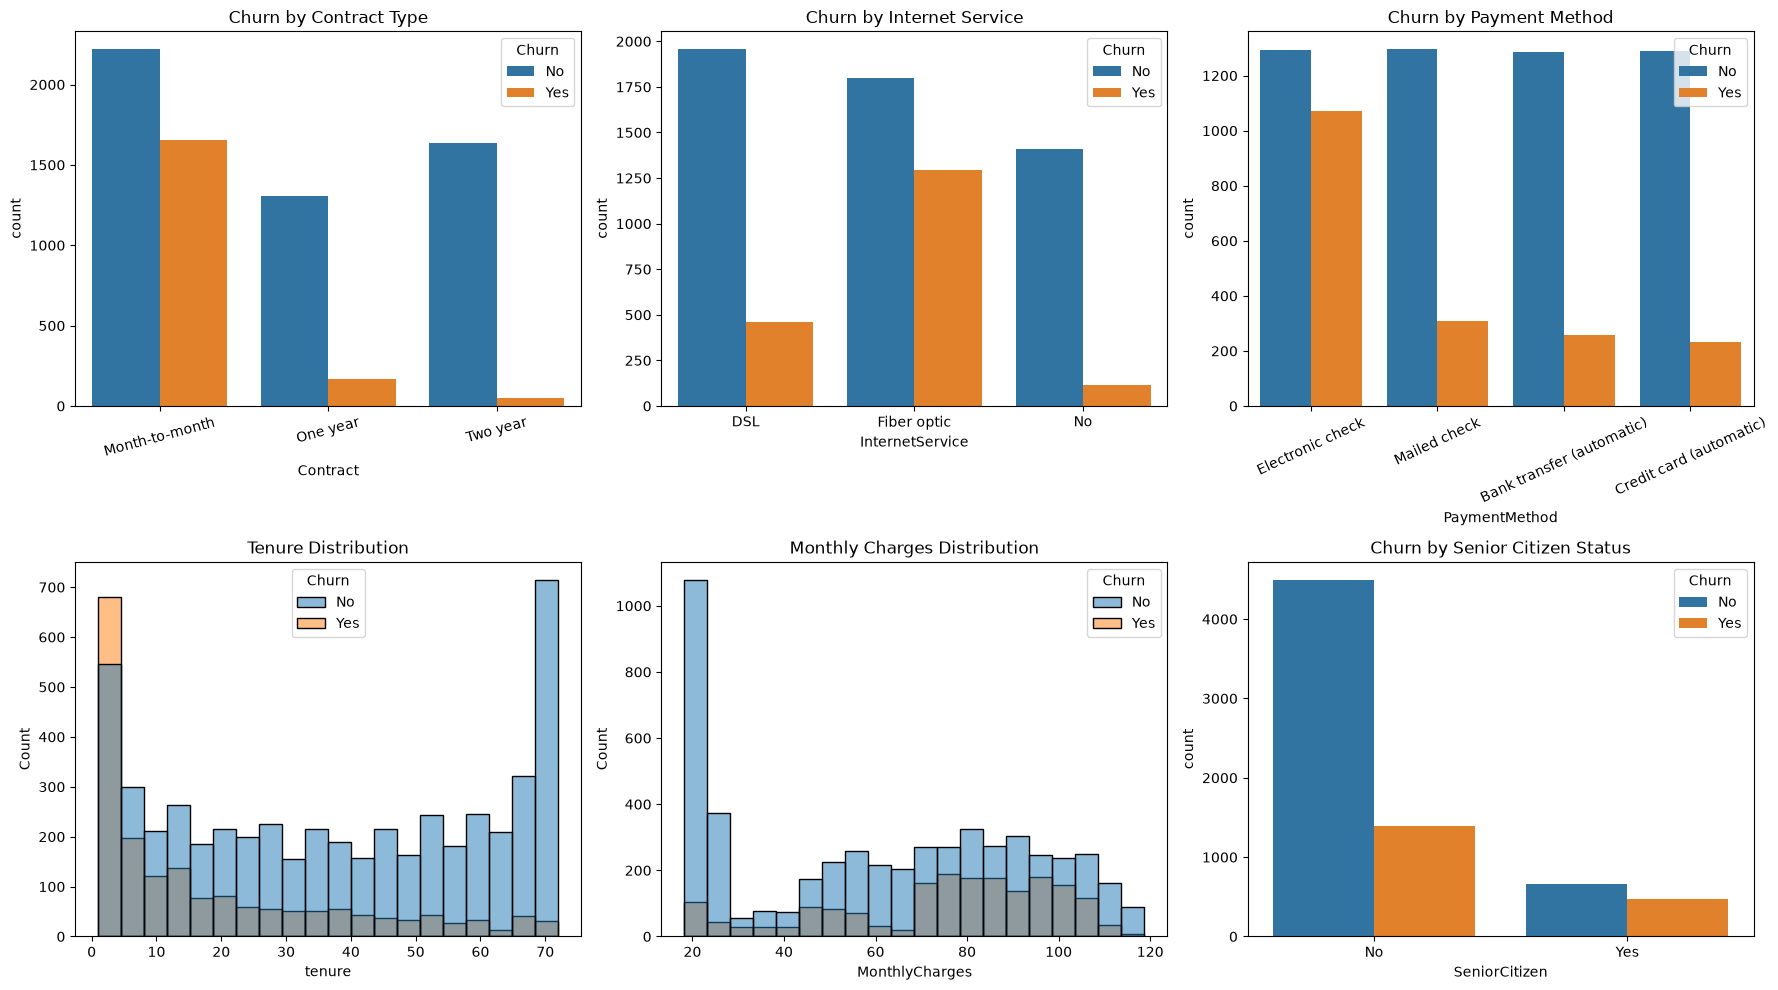

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Churn by contract
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn by Contract Type")
axes[0, 0].tick_params(axis="x", rotation=15)

# 2. Churn by internet service
sns.countplot(data=df, x="InternetService", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Churn by Internet Service")

# 3. Churn by payment method
sns.countplot(data=df, x="PaymentMethod", hue="Churn", ax=axes[0, 2])
axes[0, 2].set_title("Churn by Payment Method")
axes[0, 2].tick_params(axis="x", rotation=25)

# 4. Tenure distribution
sns.histplot(data=df, x="tenure", hue="Churn", bins=20,
             multiple="layer", ax=axes[1, 0])
axes[1, 0].set_title("Tenure Distribution")

# 5. Monthly charges distribution
sns.histplot(data=df, x="MonthlyCharges", hue="Churn",
             bins=20, multiple="layer", ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges Distribution")

# 6. Churn by senior citizen status
sns.countplot(data=df, x="SeniorCitizen", hue="Churn", ax=axes[1, 2])
axes[1, 2].set_title("Churn by Senior Citizen Status")
axes[1, 2].set_xticks([0, 1], ["No", "Yes"])

plt.tight_layout()
plt.show()

In [22]:
categorical_cols = [
    "Contract", "InternetService", "PaymentMethod",
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "TechSupport", "OnlineSecurity", "PaperlessBilling"
]

for col in categorical_cols:
    print(f"\n--- Churn Rate by {col} (%) ---")
    print(
        (df.groupby(col, observed=True)["Churn"]
           .apply(lambda x: (x == "Yes").mean() * 100)
           .round(2))
    )


--- Churn Rate by Contract (%) ---
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

--- Churn Rate by InternetService (%) ---
InternetService
DSL            19.00
Fiber optic    41.89
No              7.43
Name: Churn, dtype: float64

--- Churn Rate by PaymentMethod (%) ---
PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
Name: Churn, dtype: float64

--- Churn Rate by gender (%) ---
gender
Female    26.96
Male      26.20
Name: Churn, dtype: float64

--- Churn Rate by SeniorCitizen (%) ---
SeniorCitizen
0    23.65
1    41.68
Name: Churn, dtype: float64

--- Churn Rate by Partner (%) ---
Partner
No     32.98
Yes    19.72
Name: Churn, dtype: float64

--- Churn Rate by Dependents (%) ---
Dependents
No     31.28
Yes    15.53
Name: Churn, dtype: float64

--- Churn Rate by TechSupport (%) ---
TechSupport
No                     41

Contract - Month-to-month: 42.71% churn 
Internet Service - Fiber optic: 41.89% 
Payment Method - Electronic check: 45.29% 
Senior Citizens - Senior citizens: 41.68% 
Partner - No partner: 32.98% 
Dependents - No dependents: 31.28% 
Tech Support - No tech support: 41.65% 
Online Security - No online security: 41.78% 
Paperless Billing - Yes: 33.59% 
Gender - Similar churn rates for both genders 

In [23]:
print("Dataset shape:", df.shape)
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print(df.dtypes)

Dataset shape: (7032, 21)
Duplicate customer IDs: 0
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [ ]:
Rows: 7,032
Columns: 21
Duplicate customer IDs: 0
Missing values: 0
TotalCharges: Correctly converted to float64
Target: Churn

Preprocessing

In [25]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 19)
Testing features: (1407, 19)
Training target: (5625,)
Testing target: (1407,)


In [27]:
categorical_features = X.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print(categorical_features)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5625, 45)
Processed testing shape: (1407, 45)


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8024164889836531

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.64      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



d:\ML-Projects\customer-churn-prediction\.venv312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8038379530916845
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Accuracy: 0.7604832977967306
              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1033
           1       0.54      0.64      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.78      0.76      0.77      1407



In [32]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, gb_pred))
print(classification_report(y_test, gb_pred))

Accuracy: 0.7953091684434968
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [33]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Random Forest", rf_pred),
    ("Gradient Boosting", gb_pred)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(y_test, predictions),
        "Churn Recall": recall_score(y_test, predictions),
        "Churn F1": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).round(3)
results_df.sort_values("Churn F1", ascending=False)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1
0,Logistic Regression,0.804,0.648,0.572,0.608
1,Random Forest,0.760,0.542,0.636,0.585
2,Gradient Boosting,0.795,0.639,0.529,0.579


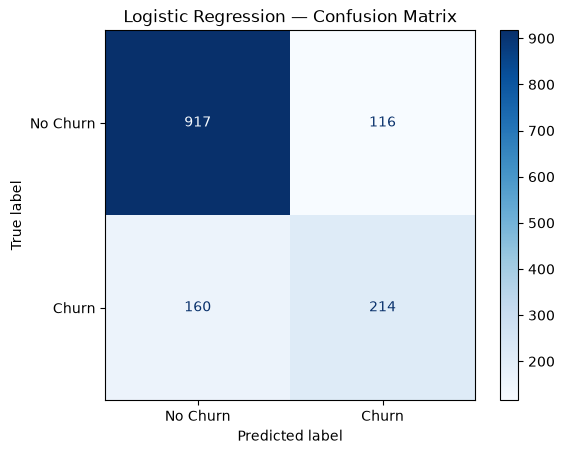

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.show()

917 — True Negative (TN): Correctly predicted customers who stayed.
116 — False Positive (FP): Predicted churn, but the customer stayed.
160 — False Negative (FN): Predicted stay, but the customer churned. These are missed churners.
214 — True Positive (TP): Correctly predicted customers who churned.

In [36]:
import joblib
joblib.dump(model, "../models/logistic_regression_churn.pkl")
print("Model saved successfully!")

Model saved successfully!


In [37]:
import joblib
loaded_model = joblib.load("../models/logistic_regression_churn.pkl")
sample_predictions = loaded_model.predict(X_test.iloc[:5])
print("Sample predictions:", sample_predictions)

Sample predictions: [0 1 0 0 0]


In [38]:
import numpy as np

original_predictions = model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

np.array_equal(original_predictions, loaded_predictions)

True

In [39]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Best parameters: {'classifier__C': 1, 'classifier__solver': 'liblinear'}
Best CV F1-score: 0.5964817699878876


In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

best_model = grid_search.best_estimator_
tuned_predictions = best_model.predict(X_test)

print("Tuned Model Results")
print("Accuracy:", accuracy_score(y_test, tuned_predictions))
print("Precision:", precision_score(y_test, tuned_predictions))
print("Recall:", recall_score(y_test, tuned_predictions))
print("F1-score:", f1_score(y_test, tuned_predictions))

Tuned Model Results
Accuracy: 0.8038379530916845
Precision: 0.6484848484848484
Recall: 0.5721925133689839
F1-score: 0.6079545454545454


In [41]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

balanced_model = clone(model)

balanced_model.set_params(
    classifier__class_weight="balanced"
)

balanced_model.fit(X_train, y_train)

balanced_predictions = balanced_model.predict(X_test)

print("Balanced Model Results")
print("Accuracy:", accuracy_score(y_test, balanced_predictions))
print("Precision:", precision_score(y_test, balanced_predictions))
print("Recall:", recall_score(y_test, balanced_predictions))
print("F1-score:", f1_score(y_test, balanced_predictions))

Balanced Model Results
Accuracy: 0.7256574271499645
Precision: 0.4901315789473684
Recall: 0.7967914438502673
F1-score: 0.6069246435845214


In [42]:
import pandas as pd

feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_model.named_steps["classifier"].coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["Absolute_Importance"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

importance.head(15)

,Feature,Coefficient,Absolute_Importance
42,num__tenure,-1.349386,1.349386
34,cat__Contract_Two year,-0.785987,0.785987
44,num__TotalCharges,0.640922,0.640922
11,cat__InternetService_DSL,-0.614660,0.614660
32,cat__Contract_Month-to-month,0.601468,0.601468
12,cat__InternetService_Fiber optic,0.558548,0.558548
43,num__MonthlyCharges,-0.503458,0.503458
35,cat__PaperlessBilling_No,-0.318278,0.318278
8,cat__MultipleLines_No,-0.304254,0.304254
15,cat__OnlineSecurity_No internet service,-0.288752,0.288752
